# Activité pratique — Bases de PyTorch

| Exercice | Sujet |
|---|---|
| 1 | Régression linéaire multiple : prédire un salaire |
| 2 | Classification MNIST avec un réseau dense (mini-lots, métriques, sauvegarde) |
| 3 | Classification des fleurs Iris |
| 4 | Classification MNIST avec un CNN |

Chaque exercice est autonome : il recrée ses données, son modèle et son optimiseur. Exécutez les cellules dans l'ordre.

---
# Exercice 1 — Régression : prédire le salaire selon l'ancienneté et l'expertise

Modèle à apprendre : `Salaire = w1 * Ancienneté + w2 * Expertise + b`

### 1. Générer les données

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé :** dimensions de `X` et `y`, salaire moyen, nuage de points coloré selon l'expertise.

Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


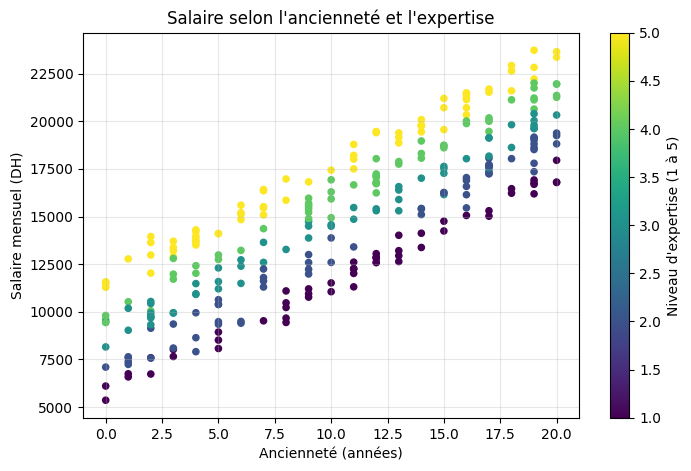

In [2]:
print("Dimensions de X :", X.shape)   # torch.Size([300, 2])
print("Dimensions de y :", y.shape)   # torch.Size([300, 1])

salaire_moyen = y.mean()
print(f"Salaire moyen : {salaire_moyen.item():.2f} DH")

plt.figure(figsize=(8, 5))
points = plt.scatter(
    X[:, 0].numpy(),          # ancienneté
    y[:, 0].numpy(),          # salaire
    c=X[:, 1].numpy(),        # couleur = expertise
    cmap="viridis",
    s=20
)
plt.colorbar(points, label="Niveau d'expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté et l'expertise")
plt.grid(True, alpha=0.3)
plt.show()

### 2. Séparer et préparer les données (80 % entraînement / 20 % test)

In [3]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print("Train :", X_train_norm.shape, y_train.shape)
print("Test  :", X_test_norm.shape, y_test.shape)

Train : torch.Size([240, 2]) torch.Size([240, 1])
Test  : torch.Size([60, 2]) torch.Size([60, 1])


### 3. Construire et entraîner le modèle

In [4]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


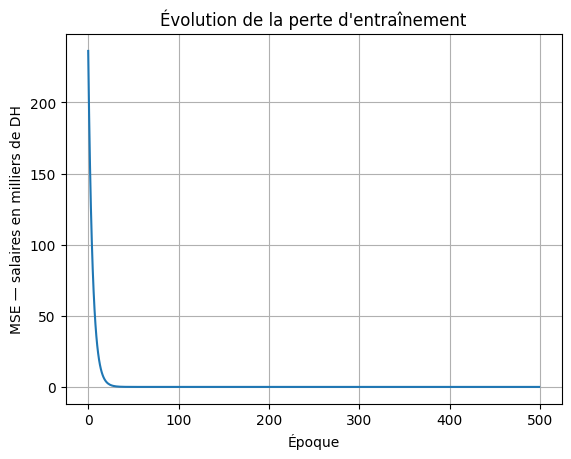

In [5]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

### 4. Évaluer les prédictions

In [6]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Erreur absolue moyenne
    mae = torch.abs(predictions_dh - salaires_reels_dh).mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


### 5. Prédire le salaire d'un nouveau salarié (7 ans d'ancienneté, expertise 4/5)

In [7]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    # Le modèle travaille en milliers de DH : on remultiplie par 1000
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")
print("Salaire théorique sans bruit : 14200 DH")

Salaire estimé : 14201.94 DH
Salaire théorique sans bruit : 14200 DH


### Questions complémentaires

**Retrouver les coefficients en unités d'origine.**

Le modèle apprend sur des entrées standardisées et des salaires en milliers de DH :

$$\frac{S}{1000} = \sum_i w_i \frac{x_i-\mu_i}{\sigma_i} + b$$

En développant, on obtient les coefficients dans l'unité d'origine :

$$w_i^{DH} = \frac{1000\,w_i}{\sigma_i}, \qquad b^{DH} = 1000\left(b - \sum_i \frac{w_i\,\mu_i}{\sigma_i}\right)$$

In [8]:
w = model.weight.detach()   # forme (1, 2)
b = model.bias.detach()     # forme (1,)

coef_dh = w * 1000 / ecart_type                        # (1, 2)
intercept_dh = 1000 * (b - (w * moyenne / ecart_type).sum())

print(f"Coefficient ancienneté : {coef_dh[0, 0].item():.1f} DH/an      (théorique : 600)")
print(f"Coefficient expertise  : {coef_dh[0, 1].item():.1f} DH/niveau  (théorique : 1500)")
print(f"Terme constant         : {intercept_dh.item():.1f} DH          (théorique : 4000)")

Coefficient ancienneté : 592.7 DH/an      (théorique : 600)
Coefficient expertise  : 1490.7 DH/niveau  (théorique : 1500)
Terme constant         : 4090.3 DH          (théorique : 4000)


**Effet du bruit et extrapolation (vérification expérimentale).**

In [9]:
def mae_selon_bruit(sigma, graine=0):
    """Régénère les données avec un bruit d'écart-type `sigma` (en DH),
    réentraîne le modèle et retourne la MAE sur le test en DH."""
    torch.manual_seed(graine)
    anc = torch.randint(0, 21, (n, 1)).float()
    exp = torch.randint(1, 6, (n, 1)).float()
    sal = 4000 + 600 * anc + 1500 * exp + torch.randn(n, 1) * sigma
    Xb, yb = torch.cat([anc, exp], dim=1), sal / 1000

    idx = torch.randperm(n)
    tr, te = idx[:limite], idx[limite:]
    m, s = Xb[tr].mean(dim=0, keepdim=True), Xb[tr].std(dim=0, keepdim=True)
    Xtr, Xte = (Xb[tr] - m) / s, (Xb[te] - m) / s

    mod = nn.Linear(2, 1)
    opt = torch.optim.SGD(mod.parameters(), lr=0.05)
    for _ in range(500):
        opt.zero_grad()
        nn.functional.mse_loss(mod(Xtr), yb[tr]).backward()
        opt.step()

    with torch.no_grad():
        return (torch.abs(mod(Xte) - yb[te]).mean() * 1000).item()

for sigma in [100, 500, 1500, 3000]:
    print(f"Bruit = {sigma:4d} DH  ->  MAE test = {mae_selon_bruit(sigma):7.1f} DH")

# Extrapolation : 40 ans d'ancienneté, expertise 4 (hors de la plage 0-20 ans)
x40 = (torch.tensor([[40.0, 4.0]]) - moyenne) / ecart_type
with torch.no_grad():
    print(f"\nPrédiction pour 40 ans d'ancienneté : {model(x40).item() * 1000:.0f} DH")

Bruit =  100 DH  ->  MAE test =    81.2 DH
Bruit =  500 DH  ->  MAE test =   405.8 DH
Bruit = 1500 DH  ->  MAE test =  1217.3 DH
Bruit = 3000 DH  ->  MAE test =  2434.5 DH

Prédiction pour 40 ans d'ancienneté : 33760 DH


**Réponses**

- **Effet d'une année d'ancienneté supplémentaire (à expertise constante)** : c'est le coefficient $w_1^{DH}$, soit environ **+600 DH par mois** par année.
- **Pourquoi la perte n'atteint jamais 0 ?** Le bruit (écart-type 500 DH = 0,5 millier de DH) est une part aléatoire des salaires qu'aucune fonction de l'ancienneté et de l'expertise ne peut expliquer. La MSE minimale atteignable est proche de la variance du bruit, soit environ $0{,}5^2 = 0{,}25$. Une perte nulle indiquerait du surapprentissage du bruit, pas un meilleur modèle.
- **Fiabilité à 40 ans d'ancienneté ?** Non. Les données s'arrêtent à 20 ans : c'est de l'**extrapolation**. Le modèle linéaire prolonge mécaniquement la droite (environ 34 000 DH) sans aucune preuve que la relation reste linéaire au-delà de la plage observée.
- **Effet d'une augmentation du bruit** : la précision se dégrade. La MAE augmente à peu près proportionnellement à l'écart-type du bruit (pour un bruit gaussien, MAE ≈ 0,8 σ), et les coefficients estimés deviennent moins stables d'un échantillon à l'autre.
- **Remarque sur l'expertise** : la traiter comme un nombre suppose qu'un niveau d'expertise supplémentaire a toujours le même effet (+1500 DH). Sur des données réelles, il faudrait le vérifier, par exemple avec un encodage one-hot par niveau.

---
# Exercice 2 — Classifier les chiffres MNIST (réseau dense)

Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

### Chargement des données et du modèle

In [10]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

torch.manual_seed(42)

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

100%|██████████| 9.91M/9.91M [00:20<00:00, 486kB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 247kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.06MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.89MB/s]


### 1. Entraînement (5 époques, `model.train()`)

In [11]:
epochs = 5
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()                 # 1. remettre les gradients à zéro
        outputs = model(images)               # 2. logits (pas de Softmax)
        loss = criterion(outputs, labels)     # 3. perte
        loss.backward()                       # 4. gradients
        optimizer.step()                      # 5. mise à jour

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

Époque 1/5 | Perte : 0.3448
Époque 2/5 | Perte : 0.1579
Époque 3/5 | Perte : 0.1081
Époque 4/5 | Perte : 0.0813
Époque 5/5 | Perte : 0.0641


### 2. Évaluation (`model.eval()` et `torch.no_grad()`)

In [12]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)

        all_preds.append(predicted_classes)
        all_labels.append(labels)

all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

accuracy = (all_preds == all_labels).float().mean().item()
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 97.41%


### 3. Métriques : Accuracy, Recall, Precision, F1-score

MNIST a 10 classes : on utilise la moyenne **macro** (moyenne simple des 10 classes). Les classes étant à peu près équilibrées, les résultats restent très proches de la moyenne pondérée.

In [13]:
y_true = all_labels.numpy()
y_pred = all_preds.numpy()

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average="macro")
rec = recall_score(y_true, y_pred, average="macro")
f1 = f1_score(y_true, y_pred, average="macro")

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f} (macro)")
print(f"Recall    : {rec:.4f} (macro)")
print(f"F1-score  : {f1:.4f} (macro)")

print()
print(classification_report(y_true, y_pred, digits=4))

Accuracy  : 0.9741
Precision : 0.9743 (macro)
Recall    : 0.9737 (macro)
F1-score  : 0.9739 (macro)

              precision    recall  f1-score   support

           0     0.9817    0.9857    0.9837       980
           1     0.9868    0.9903    0.9886      1135
           2     0.9822    0.9622    0.9721      1032
           3     0.9504    0.9861    0.9679      1010
           4     0.9776    0.9776    0.9776       982
           5     0.9906    0.9484    0.9691       892
           6     0.9632    0.9833    0.9731       958
           7     0.9803    0.9689    0.9746      1028
           8     0.9509    0.9743    0.9625       974
           9     0.9788    0.9604    0.9695      1009

    accuracy                         0.9741     10000
   macro avg     0.9743    0.9737    0.9739     10000
weighted avg     0.9744    0.9741    0.9741     10000



### 4. Matrice de confusion

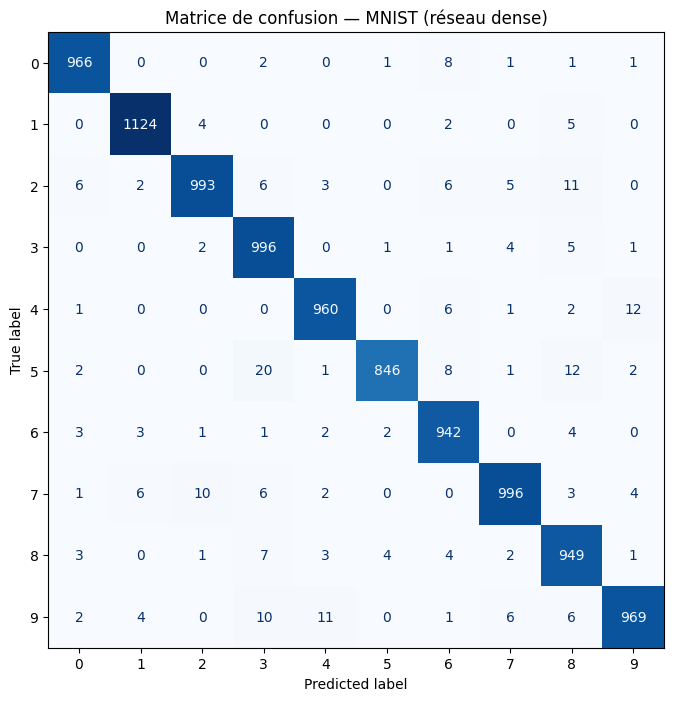

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Matrice de confusion — MNIST (réseau dense)")
plt.show()

### 5. Quelques images mal classées

Nombre d'images mal classées : 259 sur 10000


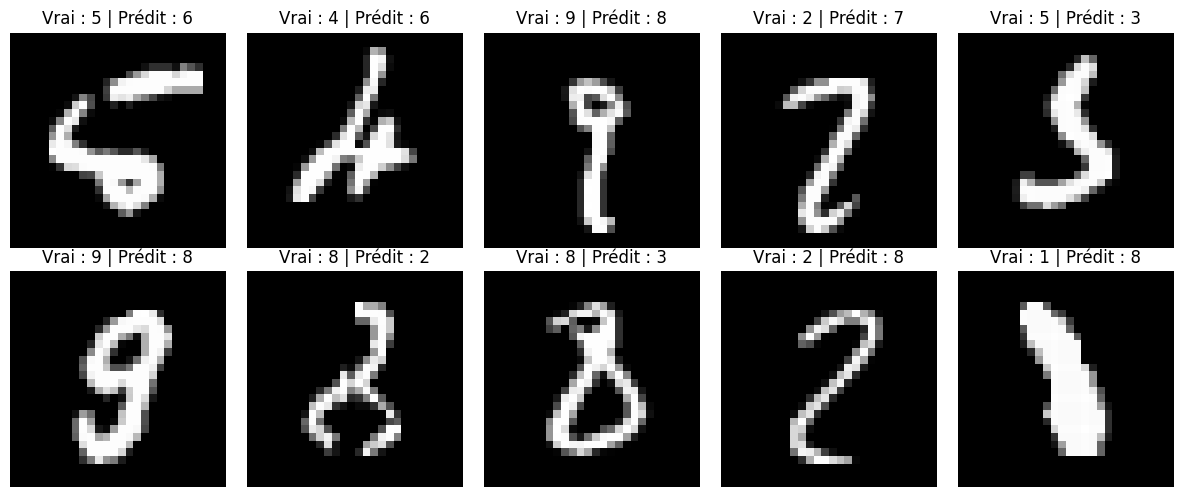

In [15]:
# test_loader n'est pas mélangé (shuffle=False) : l'ordre des prédictions
# correspond exactement à l'ordre de test_dataset.
mauvais = (all_preds != all_labels).nonzero().flatten()
print(f"Nombre d'images mal classées : {len(mauvais)} sur {len(test_dataset)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flatten(), mauvais[:10]):
    ax.imshow(test_dataset.data[idx], cmap="gray")
    ax.set_title(f"Vrai : {all_labels[idx].item()} | Prédit : {all_preds[idx].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 6. Sauvegarder et recharger un modèle (sans réentraîner)

On sauvegarde uniquement les paramètres (`state_dict`). Pour recharger, il faut recréer la **même architecture**, puis charger les poids.

In [16]:
torch.save(model.state_dict(), "mnist_mlp.pth")

# Nouvelle instance avec la même architecture, poids aléatoires
modele_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

# Chargement des poids entraînés
modele_recharge.load_state_dict(torch.load("mnist_mlp.pth", weights_only=True))
modele_recharge.eval()

correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        correct += (modele_recharge(images).argmax(dim=1) == labels).sum().item()

print(f"Accuracy du modèle rechargé : {correct / len(test_dataset):.2%}")
print("Identique au modèle d'origine :", abs(correct / len(test_dataset) - accuracy) < 1e-9)

Accuracy du modèle rechargé : 97.41%
Identique au modèle d'origine : False


---
# Exercice 3 — Classification des fleurs Iris

Objectif : entraîner un réseau de neurones pour prédire l'espèce d'une fleur (setosa, versicolor, virginica) à partir de 4 mesures.

### 1. Préparation des données

In [17]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)
print("Colonnes :", iris.feature_names)

Dimensions : torch.Size([120, 4]) torch.Size([120])
Colonnes : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


**Réponses aux questions**

- **Les quatre colonnes de `X_train`** : la longueur du sépale, la largeur du sépale, la longueur du pétale et la largeur du pétale (en cm), ici **standardisées** (moyenne 0, écart-type 1).
- **Pourquoi `torch.long` pour les étiquettes ?** `CrossEntropyLoss` attend les classes sous forme d'**indices entiers** (0, 1, 2) de type `int64` (`torch.long`), et non de nombres flottants ou de vecteurs one-hot.
- **Pourquoi ne pas ajuster le `StandardScaler` sur le test ?** Le jeu de test simule des données jamais vues. Calculer la moyenne et l'écart-type avec lui ferait fuiter de l'information du test vers l'entraînement (*data leakage*) et rendrait l'évaluation trop optimiste. On apprend les statistiques sur l'entraînement (`fit_transform`) puis on les **applique** au test (`transform`).

### 2. Construire le réseau

4 entrées (les 4 mesures), 16 neurones cachés, 3 sorties (les 3 espèces). Pas de Softmax : `CrossEntropyLoss` travaille sur les logits.

In [18]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

### 3. Entraîner le modèle

In [19]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # remettre les gradients à zéro
    optimizer.zero_grad()

    # calculer les scores prédits
    logits = model(X_train)

    # calculer la perte
    loss = criterion(logits, y_train)

    # calculer les gradients
    loss.backward()

    # mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


### 4. Évaluer le classifieur

In [20]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


### 5. Autres questions

**a) Courbe de perte**

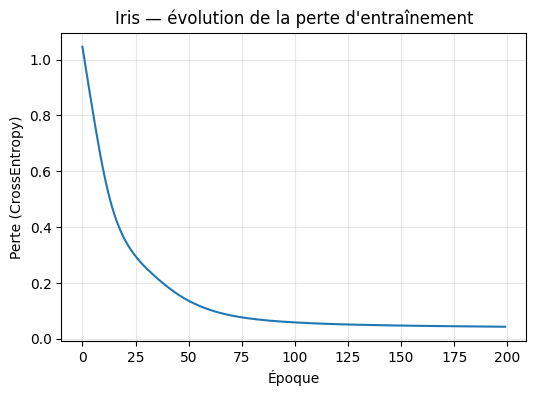

In [21]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (CrossEntropy)")
plt.title("Iris — évolution de la perte d'entraînement")
plt.grid(True, alpha=0.3)
plt.show()

**b) Matrice de confusion**

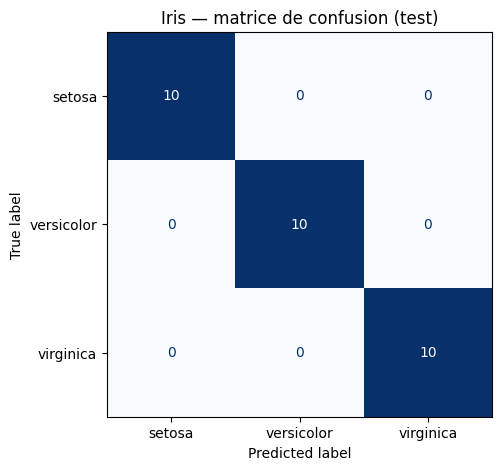

In [22]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(), predictions.numpy(),
    display_labels=iris.target_names, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Iris — matrice de confusion (test)")
plt.show()

**c) Comparaison avec un modèle sans couche cachée `nn.Linear(4, 3)`**

Réseau avec couche cachée (4-16-3) : accuracy = 100.0%
Modèle linéaire nn.Linear(4, 3)    : accuracy = 90.0%


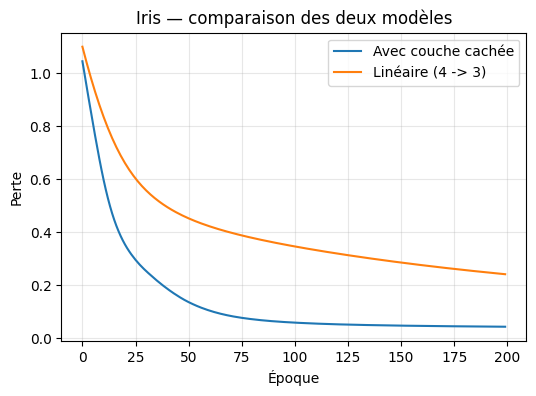

In [23]:
def entrainer_et_evaluer(modele, epochs=200, lr=0.01):
    """Entraîne `modele` sur Iris et retourne (pertes, accuracy test)."""
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    pertes = []

    modele.train()
    for _ in range(epochs):
        opt.zero_grad()
        perte = crit(modele(X_train), y_train)
        perte.backward()
        opt.step()
        pertes.append(perte.item())

    modele.eval()
    with torch.no_grad():
        acc = (modele(X_test).argmax(dim=1) == y_test).float().mean().item()
    return pertes, acc

torch.manual_seed(42)
reseau_cache = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 3))
pertes_cache, acc_cache = entrainer_et_evaluer(reseau_cache)

torch.manual_seed(42)
modele_lineaire = nn.Linear(4, 3)
pertes_lin, acc_lin = entrainer_et_evaluer(modele_lineaire)

print(f"Réseau avec couche cachée (4-16-3) : accuracy = {acc_cache:.1%}")
print(f"Modèle linéaire nn.Linear(4, 3)    : accuracy = {acc_lin:.1%}")

plt.figure(figsize=(6, 4))
plt.plot(pertes_cache, label="Avec couche cachée")
plt.plot(pertes_lin, label="Linéaire (4 -> 3)")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.title("Iris — comparaison des deux modèles")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Sur Iris, les classes sont presque linéairement séparables (seules *versicolor* et *virginica* se chevauchent un peu). Un modèle linéaire suffit donc souvent à obtenir des résultats très proches de ceux du réseau avec couche cachée. La couche cachée devient vraiment utile quand la frontière entre les classes n'est pas linéaire.

**d) Prédire l'espèce d'une nouvelle fleur `[5.1, 3.5, 1.4, 0.2]`**

Il faut d'abord la normaliser avec le **même scaler** que celui de l'entraînement.

In [24]:
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]
nouvelle_fleur_norm = torch.tensor(
    scaler.transform(nouvelle_fleur), dtype=torch.float32
)

model.eval()
with torch.no_grad():
    logits = model(nouvelle_fleur_norm)
    probabilites = torch.softmax(logits, dim=1)   # Softmax seulement pour l'affichage
    classe = logits.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])
for nom, p in zip(iris.target_names, probabilites[0]):
    print(f"  {nom:<12s} {p.item():.1%}")

Espèce prédite : setosa
  setosa       100.0%
  versicolor   0.0%
  virginica    0.0%


---
# Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

### 1. Chargement des données

In [25]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Réponses aux questions**

- **Les quatre dimensions de `images`** `[64, 1, 28, 28]` : `[taille du lot, nombre de canaux, hauteur, largeur]`. Ici 64 images par lot, 1 canal (niveaux de gris, une image couleur en aurait 3), 28 × 28 pixels.
- **Pourquoi `shuffle=True` pour l'entraînement ?** Pour que les lots soient différents à chaque époque et ne dépendent pas de l'ordre du jeu de données (par exemple des chiffres rangés par classe). Les gradients estimés sont ainsi moins corrélés d'un lot à l'autre, l'apprentissage est plus stable et généralise mieux. Pour le test, l'ordre n'a aucune importance : `shuffle=False`.

### 2. Visualiser quelques images

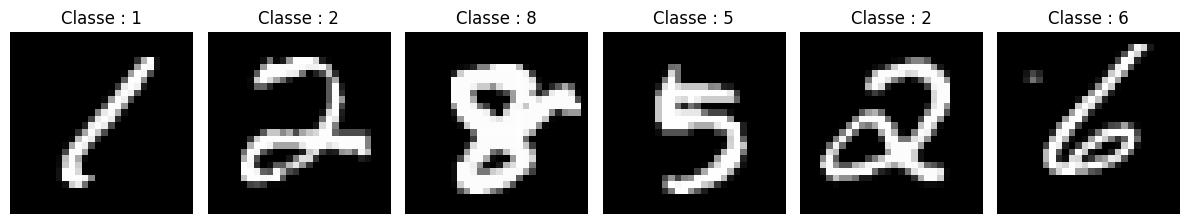

In [26]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : { labels[i].item() }")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 3. Construire le CNN

In [27]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,       # image en niveaux de gris
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),     # 16 x 14 x 14

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)      # 32 x 7 x 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Question : pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?**

- Les convolutions avec `kernel_size=3` et `padding=1` **conservent** la taille spatiale.
- Chaque `MaxPool2d(2)` **divise par 2** la hauteur et la largeur : 28 → 14 → 7.
- La dernière convolution produit **32 canaux** (32 filtres).
- Après `Flatten`, chaque image devient donc un vecteur de 32 × 7 × 7 = **1568** valeurs.

### 4. Entraîner le réseau

In [28]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1679
Époque 2/3 | Perte : 0.0483
Époque 3/3 | Perte : 0.0351


### 5. Évaluer sur le jeu de test

In [29]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.90%


### Autres questions

**a) Afficher 10 images mal classées (vraie classe et prédiction)**

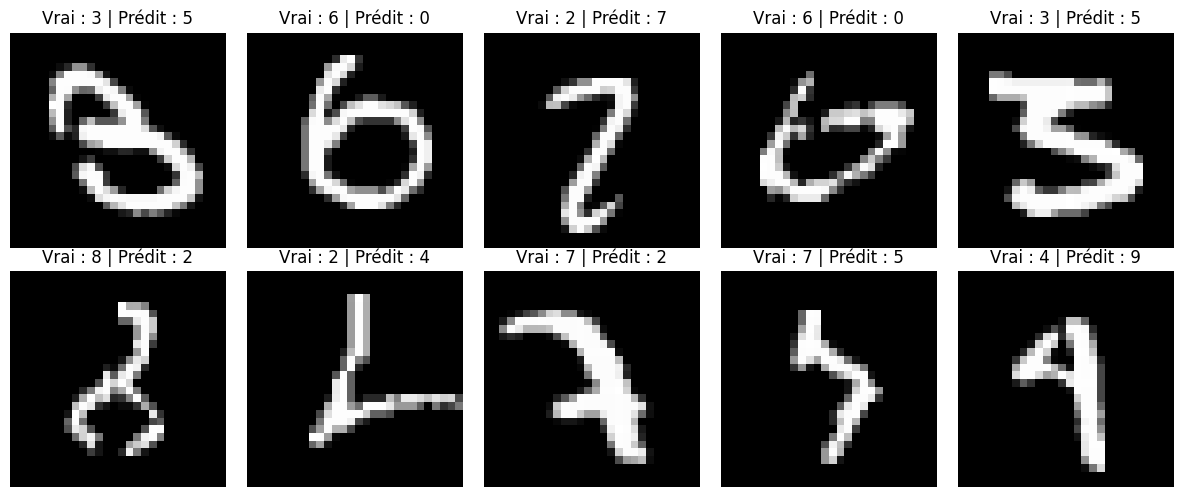

In [30]:
erreurs = []   # liste de (image, vraie classe, prédiction)

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        for img, vrai, pred in zip(images, labels, predictions):
            if vrai != pred:
                erreurs.append((img, vrai.item(), pred.item()))
        if len(erreurs) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (img, vrai, pred) in zip(axes.flatten(), erreurs[:10]):
    ax.imshow((img[0] * 0.3081 + 0.1307).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {vrai} | Prédit : {pred}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**b) Ajouter une couche `Dropout` avant la dernière couche linéaire**

`Dropout` met aléatoirement à zéro une fraction des activations **uniquement pendant l'entraînement** (`model.train()`) ; il est désactivé en `model.eval()`. Cela limite le surapprentissage.

In [31]:
class MNISTClassifierDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p),            # <- avant la dernière couche linéaire
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def entrainer(modele, epochs=3, lr=0.001):
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    for epoch in range(epochs):
        modele.train()
        total = 0.0
        for imgs, labs in train_loader:
            imgs, labs = imgs.to(device), labs.to(device)
            opt.zero_grad()
            perte = crit(modele(imgs), labs)
            perte.backward()
            opt.step()
            total += perte.item() * imgs.size(0)
        print(f"Époque {epoch + 1}/{epochs} | Perte : {total / len(train_dataset):.4f}")


def evaluer(modele):
    modele.eval()
    bons = 0
    with torch.no_grad():
        for imgs, labs in test_loader:
            imgs, labs = imgs.to(device), labs.to(device)
            bons += (modele(imgs).argmax(dim=1) == labs).sum().item()
    return bons / len(test_dataset)


torch.manual_seed(42)
model_dropout = MNISTClassifierDropout(p=0.5).to(device)
entrainer(model_dropout, epochs=3)

print(f"\nAccuracy CNN sans Dropout : {evaluer(model):.2%}")
print(f"Accuracy CNN avec Dropout : {evaluer(model_dropout):.2%}")

Époque 1/3 | Perte : 0.2482
Époque 2/3 | Perte : 0.0870
Époque 3/3 | Perte : 0.0692

Accuracy CNN sans Dropout : 98.90%
Accuracy CNN avec Dropout : 98.88%


**c) Sauvegarder et recharger les paramètres**

In [32]:
torch.save(model.state_dict(), "mnist_cnn.pth")

# Recréer la même architecture, puis charger les poids sauvegardés
modele_recharge = MNISTClassifier().to(device)
modele_recharge.load_state_dict(
    torch.load("mnist_cnn.pth", map_location=device, weights_only=True)
)
modele_recharge.eval()

print(f"Accuracy du modèle rechargé : {evaluer(modele_recharge):.2%}")
print(f"Accuracy du modèle d'origine : {evaluer(model):.2%}")

Accuracy du modèle rechargé : 98.90%
Accuracy du modèle d'origine : 98.90%


**Remarque :** les résultats exacts (perte, accuracy) varient légèrement d'une exécution à l'autre selon le matériel et la graine aléatoire. Pour ce CNN, on attend généralement plus de 98 % d'accuracy après 3 époques.